In [1]:
import pyscf
import numpy as np
import torch
from pyscf import gto, scf, dft
import matplotlib.pyplot as plt

In [2]:
NiO_data = np.load("/home/ihor/projects/MLGuessQC/mlguess/results/NiO_LANL2DZ_veff/veff_epoch_1439.npz")

In [3]:
for key in NiO_data:
    print(f"{key}")

n_atom
atom_types
coords
ground_truth
predictions


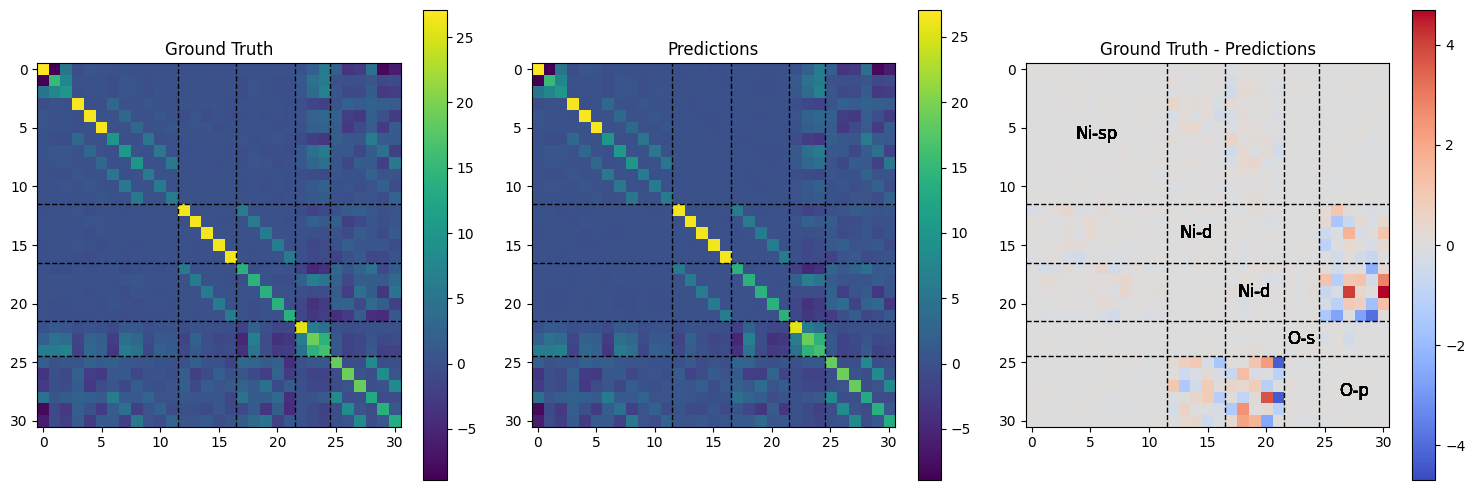

In [28]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Reshape arrays to square matrices
gt = NiO_data['ground_truth'].reshape(int(np.sqrt(NiO_data['ground_truth'].size)), -1)
pred = NiO_data['predictions'].reshape(int(np.sqrt(NiO_data['predictions'].size)), -1)
diff = gt - pred

# Plot ground_truth
im0 = axs[0].imshow(gt)
axs[0].set_title('Ground Truth')
plt.colorbar(im0, ax=axs[0])

# Plot predictions
im1 = axs[1].imshow(pred)
axs[1].set_title('Predictions')
plt.colorbar(im1, ax=axs[1])

# Plot difference
im2 = axs[2].imshow(diff, cmap='coolwarm', vmin=-np.max(np.abs(diff)), vmax=np.max(np.abs(diff)))
axs[2].set_title('Ground Truth - Predictions')
plt.colorbar(im2, ax=axs[2])

# Add vertical and horizontal grid lines at 12, 17, 20
for ax in axs:
    for pos in [12, 17, 22, 25]:
        ax.axvline(pos - 0.5, color='k', linestyle='--', linewidth=1)
        ax.axhline(pos - 0.5, color='k', linestyle='--', linewidth=1)

        #axs[0].text(12, 12, f"Ni-d", color="white", ha="center", va="center", fontsize=12, fontweight='bold')
        #axs[1].text(12, 12, f"{pred[12, 12]:.2f}", color="white", ha="center", va="center", fontsize=12, fontweight='bold')
        axs[2].text(5.5, 5.5, f"Ni-sp", color="k", ha="center", va="center", fontsize=12)
        axs[2].text(14, 14, f"Ni-d", color="k", ha="center", va="center", fontsize=12)
        axs[2].text(19, 19, f"Ni-d", color="k", ha="center", va="center", fontsize=12)
        axs[2].text(23, 23, f"O-s", color="k", ha="center", va="center", fontsize=12)
        axs[2].text(27.5, 27.5, f"O-p", color="k", ha="center", va="center", fontsize=12)
plt.tight_layout()
plt.show()

In [29]:
tmQM_output = np.load('/home/ihor/projects/MLGuessQC/mlguess/results/tmQM_dft_acc_est_overfit_fctp_lin_veff/veff_epoch_20949.npz')

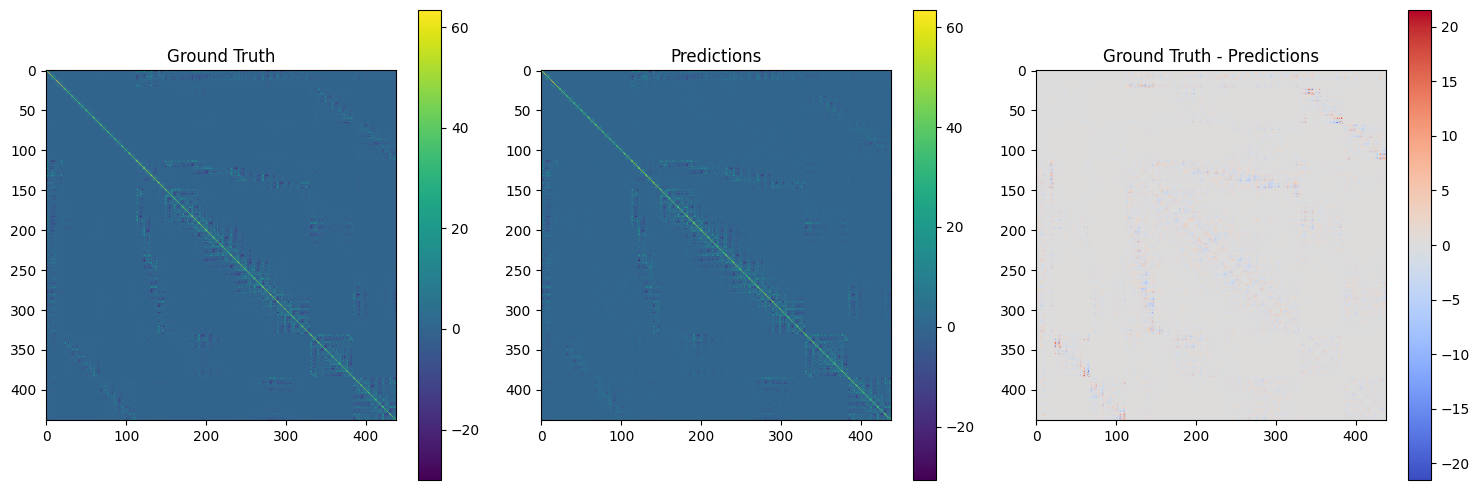

In [31]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Reshape arrays to square matrices
gt = tmQM_output['ground_truth'].reshape(int(np.sqrt(tmQM_output['ground_truth'].size)), -1)
pred = tmQM_output['predictions'].reshape(int(np.sqrt(tmQM_output['predictions'].size)), -1)
diff = gt - pred

# Plot ground_truth
im0 = axs[0].imshow(gt)
axs[0].set_title('Ground Truth')
plt.colorbar(im0, ax=axs[0])

# Plot predictions
im1 = axs[1].imshow(pred)
axs[1].set_title('Predictions')
plt.colorbar(im1, ax=axs[1])

# Plot difference
im2 = axs[2].imshow(diff, cmap='coolwarm', vmin=-np.max(np.abs(diff)), vmax=np.max(np.abs(diff)))
axs[2].set_title('Ground Truth - Predictions')
plt.colorbar(im2, ax=axs[2])

# # Add vertical and horizontal grid lines at 12, 17, 20
# for ax in axs:
#     for pos in [12, 17, 22, 25]:
#         ax.axvline(pos - 0.5, color='k', linestyle='--', linewidth=1)
#         ax.axhline(pos - 0.5, color='k', linestyle='--', linewidth=1)

#         #axs[0].text(12, 12, f"Ni-d", color="white", ha="center", va="center", fontsize=12, fontweight='bold')
#         #axs[1].text(12, 12, f"{pred[12, 12]:.2f}", color="white", ha="center", va="center", fontsize=12, fontweight='bold')
#         axs[2].text(5.5, 5.5, f"Ni-sp", color="k", ha="center", va="center", fontsize=12)
#         axs[2].text(14, 14, f"Ni-d", color="k", ha="center", va="center", fontsize=12)
#         axs[2].text(19, 19, f"Ni-d", color="k", ha="center", va="center", fontsize=12)
#         axs[2].text(23, 23, f"O-s", color="k", ha="center", va="center", fontsize=12)
#         axs[2].text(27.5, 27.5, f"O-p", color="k", ha="center", va="center", fontsize=12)
plt.tight_layout()
plt.show()

In [32]:
tmQM_output['atom_types']

array([28,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  7,  7,  7,  7,  6,  1,
        6,  1,  6,  1,  6,  6,  6,  6,  1,  6,  1,  6,  6,  6,  1,  6,  1,
        6,  6,  6,  6,  1,  6,  1,  6,  1,  6,  6,  6,  6,  6,  6,  6,  6,
        6,  6,  6,  6])

In [34]:
from ase import Atoms
import nglview as nv

In [35]:



atoms = Atoms(
    numbers=tmQM_output['atom_types'],  # Use the first molecule's atomic numbers
    positions=tmQM_output['coords'],  # Use the first molecule's positions
)

# Display the atoms using nglview
view = nv.show_ase(atoms)
view

NGLWidget()

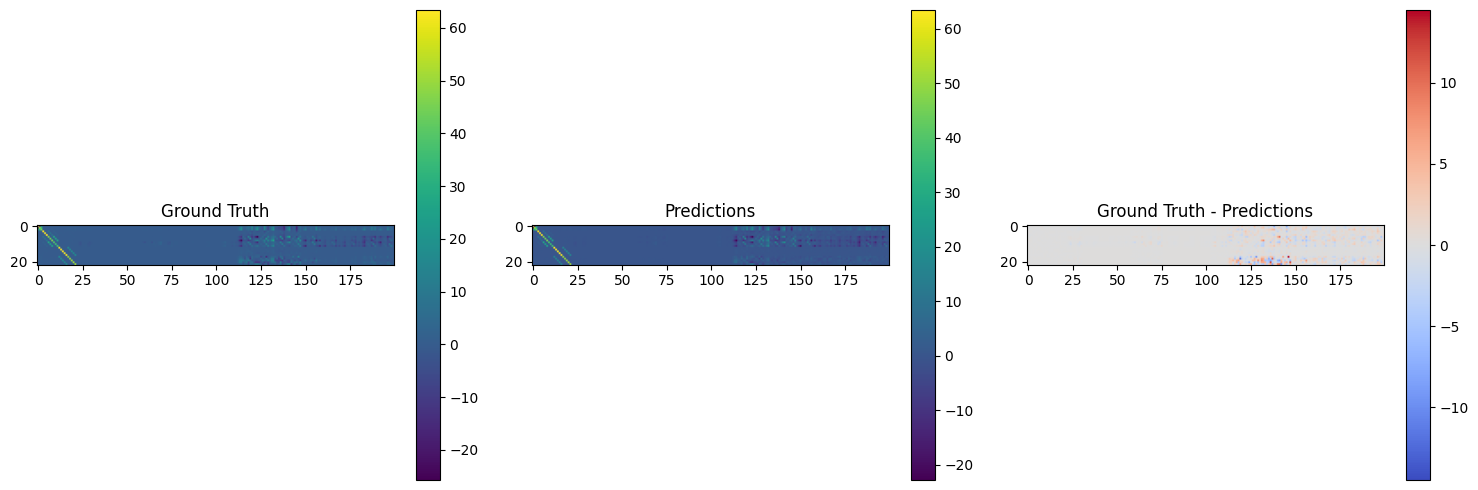

In [37]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Reshape arrays to square matrices
gt = tmQM_output['ground_truth'].reshape(int(np.sqrt(tmQM_output['ground_truth'].size)), -1)
pred = tmQM_output['predictions'].reshape(int(np.sqrt(tmQM_output['predictions'].size)), -1)
diff = gt - pred

gt = gt[:22, :200]
pred = pred[:22, :200]
diff = diff[:22, :200]

# Plot ground_truth
im0 = axs[0].imshow(gt)
axs[0].set_title('Ground Truth')
plt.colorbar(im0, ax=axs[0])

# Plot predictions
im1 = axs[1].imshow(pred)
axs[1].set_title('Predictions')
plt.colorbar(im1, ax=axs[1])

# Plot difference
im2 = axs[2].imshow(diff, cmap='coolwarm', vmin=-np.max(np.abs(diff)), vmax=np.max(np.abs(diff)))
axs[2].set_title('Ground Truth - Predictions')
plt.colorbar(im2, ax=axs[2])

# # Add vertical and horizontal grid lines at 12, 17, 20
# for ax in axs:
#     for pos in [12, 17, 22, 25]:
#         ax.axvline(pos - 0.5, color='k', linestyle='--', linewidth=1)
#         ax.axhline(pos - 0.5, color='k', linestyle='--', linewidth=1)

#         #axs[0].text(12, 12, f"Ni-d", color="white", ha="center", va="center", fontsize=12, fontweight='bold')
#         #axs[1].text(12, 12, f"{pred[12, 12]:.2f}", color="white", ha="center", va="center", fontsize=12, fontweight='bold')
#         axs[2].text(5.5, 5.5, f"Ni-sp", color="k", ha="center", va="center", fontsize=12)
#         axs[2].text(14, 14, f"Ni-d", color="k", ha="center", va="center", fontsize=12)
#         axs[2].text(19, 19, f"Ni-d", color="k", ha="center", va="center", fontsize=12)
#         axs[2].text(23, 23, f"O-s", color="k", ha="center", va="center", fontsize=12)
#         axs[2].text(27.5, 27.5, f"O-p", color="k", ha="center", va="center", fontsize=12)
plt.tight_layout()
plt.show()

# OF2

In [47]:
OF2_output = np.load('/home/ihor/projects/MLGuessQC/mlguess/results/tmQM_dft_acc_est_overfit_fctp_lin_veff/veff_epoch_2539.npz')

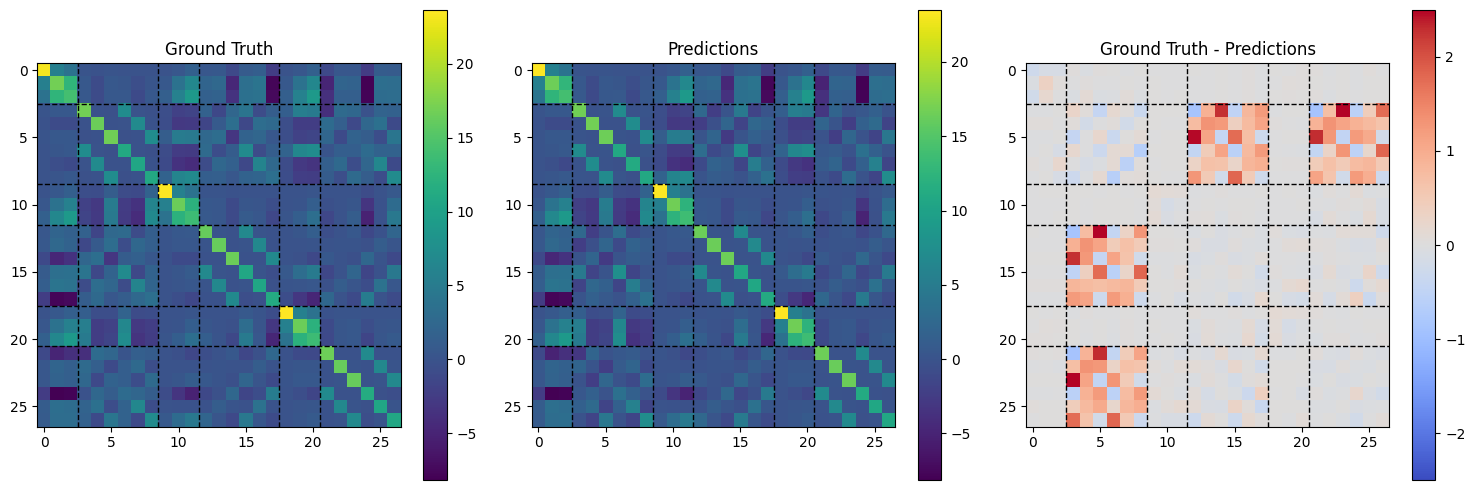

In [48]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Reshape arrays to square matrices
gt = OF2_output['ground_truth'].reshape(int(np.sqrt(OF2_output['ground_truth'].size)), -1)
pred = OF2_output['predictions'].reshape(int(np.sqrt(OF2_output['predictions'].size)), -1)
diff = gt - pred

# Plot ground_truth
im0 = axs[0].imshow(gt)
axs[0].set_title('Ground Truth')
plt.colorbar(im0, ax=axs[0])

# Plot predictions
im1 = axs[1].imshow(pred)
axs[1].set_title('Predictions')
plt.colorbar(im1, ax=axs[1])

# Plot difference
im2 = axs[2].imshow(diff, cmap='coolwarm', vmin=-np.max(np.abs(diff)), vmax=np.max(np.abs(diff)))
axs[2].set_title('Ground Truth - Predictions')
plt.colorbar(im2, ax=axs[2])

# # Add vertical and horizontal grid lines at 12, 17, 20
for ax in axs:
    for pos in [3, 9, 12, 18, 21]:
        ax.axvline(pos - 0.5, color='k', linestyle='--', linewidth=1)
        ax.axhline(pos - 0.5, color='k', linestyle='--', linewidth=1)

        #axs[0].text(12, 12, f"Ni-d", color="white", ha="center", va="center", fontsize=12, fontweight='bold')
        #axs[1].text(12, 12, f"{pred[12, 12]:.2f}", color="white", ha="center", va="center", fontsize=12, fontweight='bold')
        # axs[2].text(5.5, 5.5, f"Ni-sp", color="k", ha="center", va="center", fontsize=12)
        # axs[2].text(14, 14, f"Ni-d", color="k", ha="center", va="center", fontsize=12)
        # axs[2].text(19, 19, f"Ni-d", color="k", ha="center", va="center", fontsize=12)
        # axs[2].text(23, 23, f"O-s", color="k", ha="center", va="center", fontsize=12)
        # axs[2].text(27.5, 27.5, f"O-p", color="k", ha="center", va="center", fontsize=12)
plt.tight_layout()
plt.show()

In [78]:
OF2_STO3G_output = np.load('/home/ihor/projects/MLGuessQC/mlguess/results/tmQM_dft_acc_est_overfit_fctp_lin_veff/veff_epoch_1879.npz')

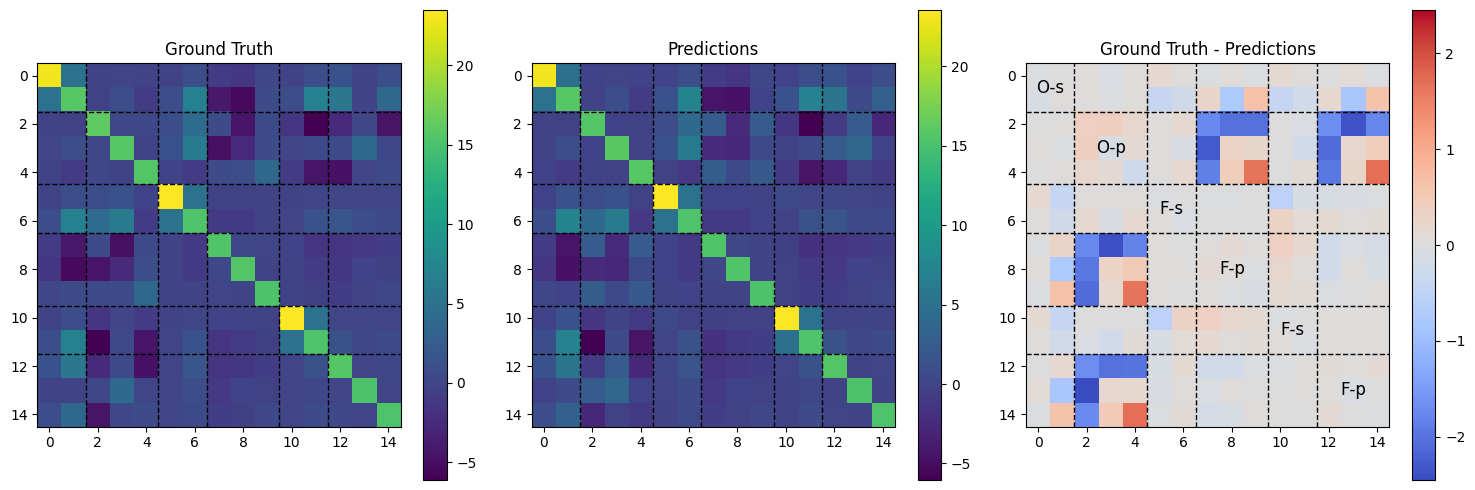

In [79]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Reshape arrays to square matrices
gt = OF2_STO3G_output['ground_truth'].reshape(int(np.sqrt(OF2_STO3G_output['ground_truth'].size)), -1)
pred = OF2_STO3G_output['predictions'].reshape(int(np.sqrt(OF2_STO3G_output['predictions'].size)), -1)
diff = gt - pred

# Plot ground_truth
im0 = axs[0].imshow(gt)
axs[0].set_title('Ground Truth')
plt.colorbar(im0, ax=axs[0])

# Plot predictions
im1 = axs[1].imshow(pred)
axs[1].set_title('Predictions')
plt.colorbar(im1, ax=axs[1])

# Plot difference
im2 = axs[2].imshow(diff, cmap='coolwarm', vmin=-np.max(np.abs(diff)), vmax=np.max(np.abs(diff)))
axs[2].set_title('Ground Truth - Predictions')
plt.colorbar(im2, ax=axs[2])

# # Add vertical and horizontal grid lines at 12, 17, 20
for ax in axs:
    for pos in [2, 5, 7, 10, 12]:
        ax.axvline(pos - 0.5, color='k', linestyle='--', linewidth=1)
        ax.axhline(pos - 0.5, color='k', linestyle='--', linewidth=1)

        #axs[0].text(12, 12, f"Ni-d", color="white", ha="center", va="center", fontsize=12, fontweight='bold')
        #axs[1].text(12, 12, f"{pred[12, 12]:.2f}", color="white", ha="center", va="center", fontsize=12, fontweight='bold')
axs[2].text(0.5, 0.5, f"O-s", color="k", ha="center", va="center", fontsize=12)
axs[2].text(3., 3., f"O-p", color="k", ha="center", va="center", fontsize=12)

axs[2].text(5.5, 5.5, f"F-s", color="k", ha="center", va="center", fontsize=12)
axs[2].text(8., 8., f"F-p", color="k", ha="center", va="center", fontsize=12)

axs[2].text(10.5, 10.5, f"F-s", color="k", ha="center", va="center", fontsize=12)
axs[2].text(13., 13., f"F-p", color="k", ha="center", va="center", fontsize=12)

plt.tight_layout()
plt.show()

In [81]:
print("Ground Truth (PySCF calculation)")
print(gt)
print("Predictions")
print(pred)

Ground Truth (PySCF calculation)
[[ 2.29886818e+01  4.91472530e+00 -2.60522403e-02  9.26850140e-02
  -7.56423473e-02  7.48327948e-05  1.01924634e+00 -9.88006055e-01
  -1.35745478e+00  1.83730289e-01  7.48324164e-05  1.01924694e+00
   1.38416851e+00 -5.19142486e-02  9.66427505e-01]
 [ 4.91472530e+00  1.58136206e+01 -2.92006582e-01  1.03882921e+00
  -8.47767770e-01  1.02066147e+00  6.89578819e+00 -4.08927917e+00
  -5.37516785e+00  6.08082533e-01  1.02066159e+00  6.89579487e+00
   5.61054230e+00 -3.68082449e-02  3.80852580e+00]
 [-2.60522403e-02 -2.92006582e-01  1.60881577e+01  3.05952698e-01
   2.81142205e-01  1.00186861e+00  4.24129725e+00  6.87513649e-01
  -4.41029930e+00  5.76914668e-01 -1.40748811e+00 -6.11018896e+00
  -2.58664203e+00  1.62296876e-01 -4.49657297e+00]
 [ 9.26850140e-02  1.03882921e+00  3.05952698e-01  1.58393536e+01
  -7.66784996e-02  1.38451052e+00  6.17283726e+00 -4.76072741e+00
  -2.43907928e+00  7.75884271e-01  5.85061871e-02  4.75837350e-01
   5.12728631e-01  3.9

In [ ]:
print(pred)

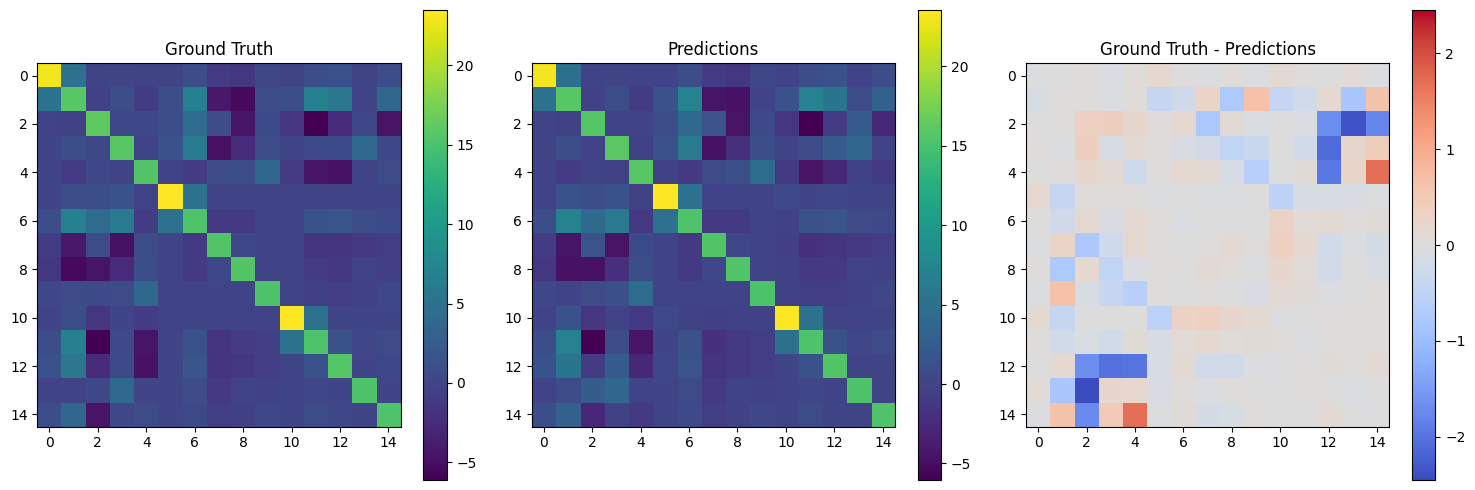

In [67]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Reshape arrays to square matrices
gt = OF2_STO3G_output['ground_truth'].reshape(int(np.sqrt(OF2_STO3G_output['ground_truth'].size)), -1)
pred = OF2_STO3G_output['predictions'].reshape(int(np.sqrt(OF2_STO3G_output['predictions'].size)), -1)
pred[7:10, 2:5] += (gt[7:10, 2:5] +  gt[12:15, 2:5]) / 2
pred[2:5, 7:10] += (gt[2:5, 7:10] +  gt[2:5, 12:15]) / 2
#pred[12:15, 7:10] += (gt[12:15, 7:10] +  gt[7:10, 12:15]) / 2
#pred[7:10, 12:15] += (gt[ 
diff = gt - pred
# Plot ground_truth
im0 = axs[0].imshow(gt)
axs[0].set_title('Ground Truth')
plt.colorbar(im0, ax=axs[0])

# Plot predictions
im1 = axs[1].imshow(pred)
axs[1].set_title('Predictions')
plt.colorbar(im1, ax=axs[1])

# Plot difference
im2 = axs[2].imshow(diff, cmap='coolwarm', vmin=-np.max(np.abs(diff)), vmax=np.max(np.abs(diff)))
axs[2].set_title('Ground Truth - Predictions')
plt.colorbar(im2, ax=axs[2])

plt.tight_layout()
plt.show()